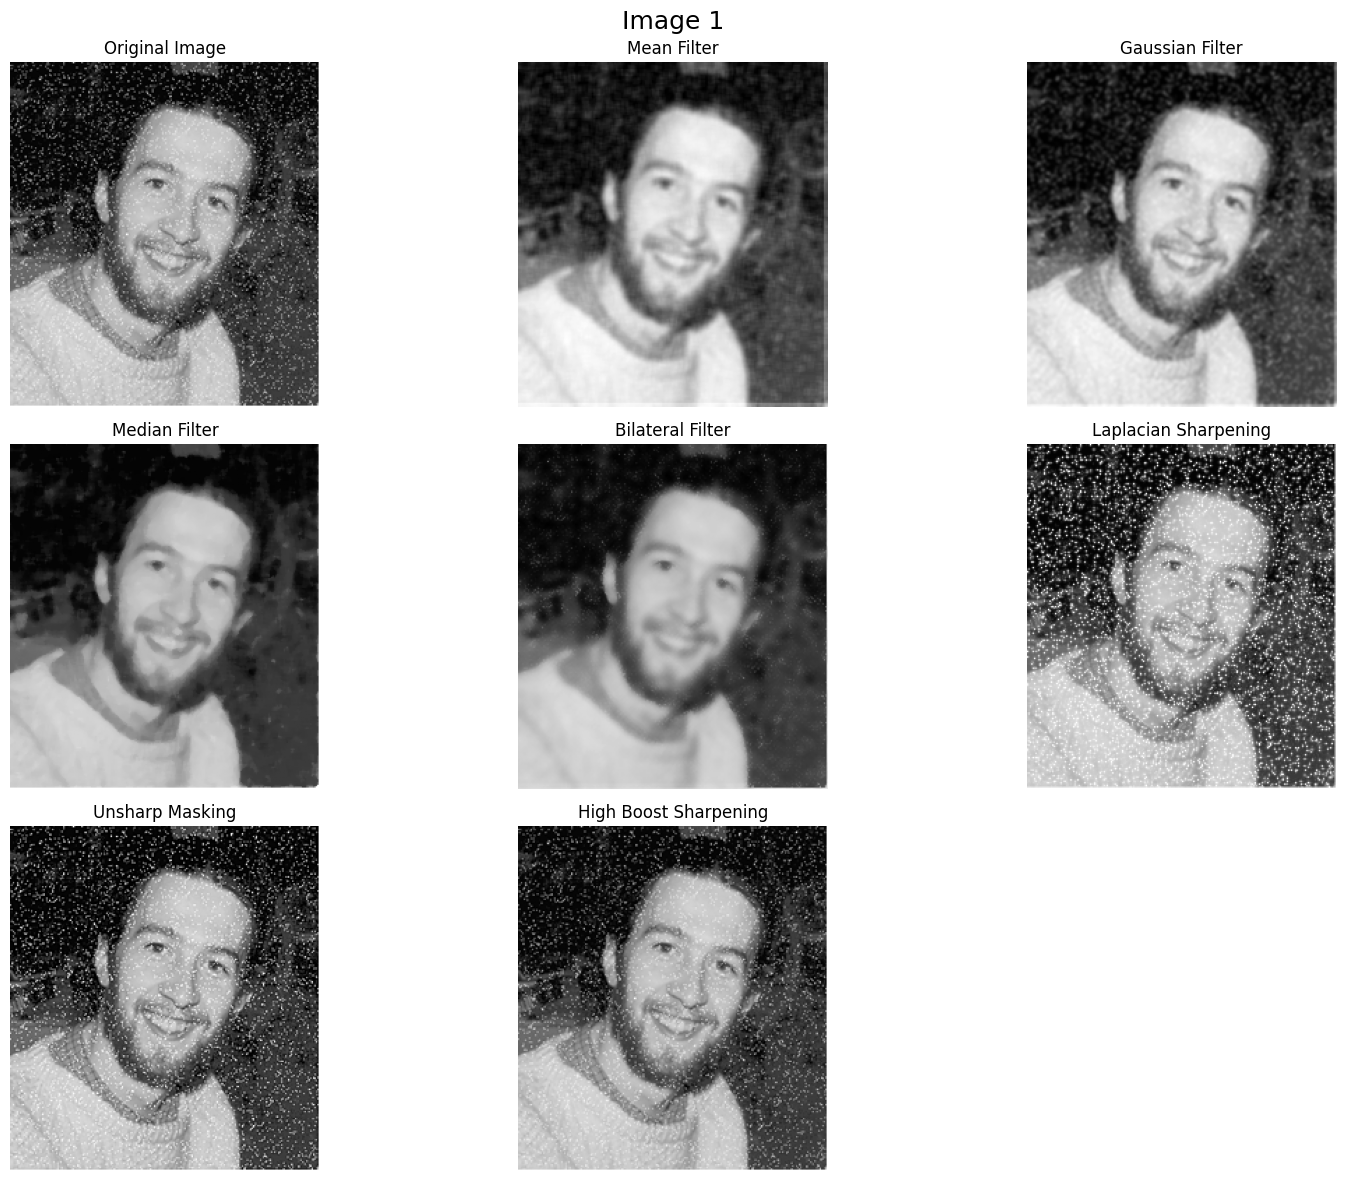

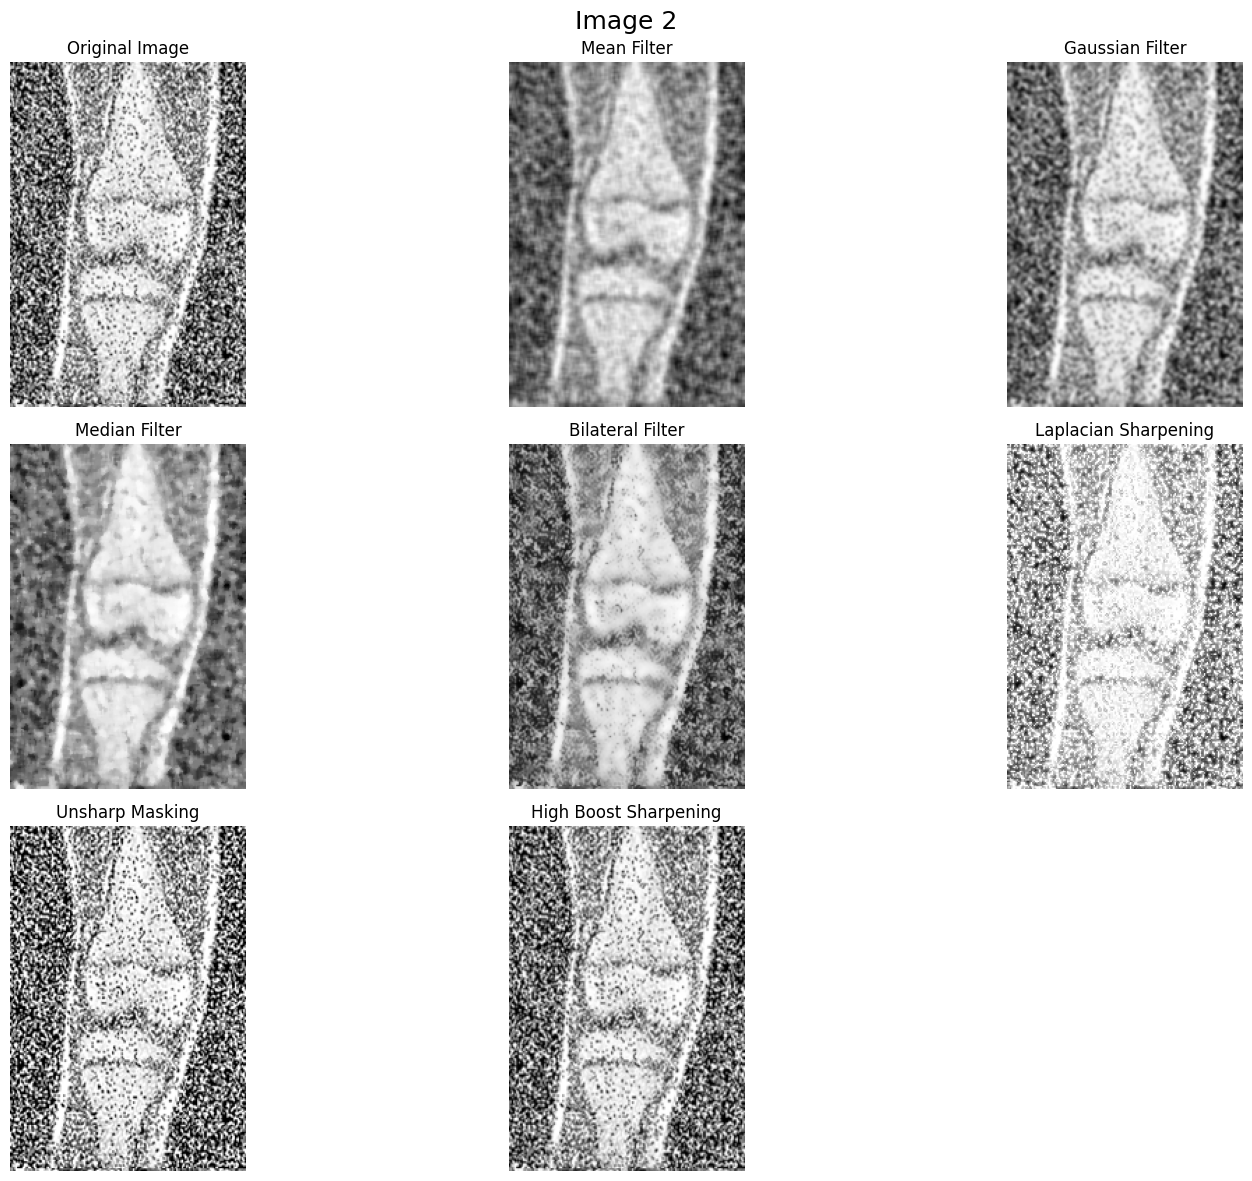

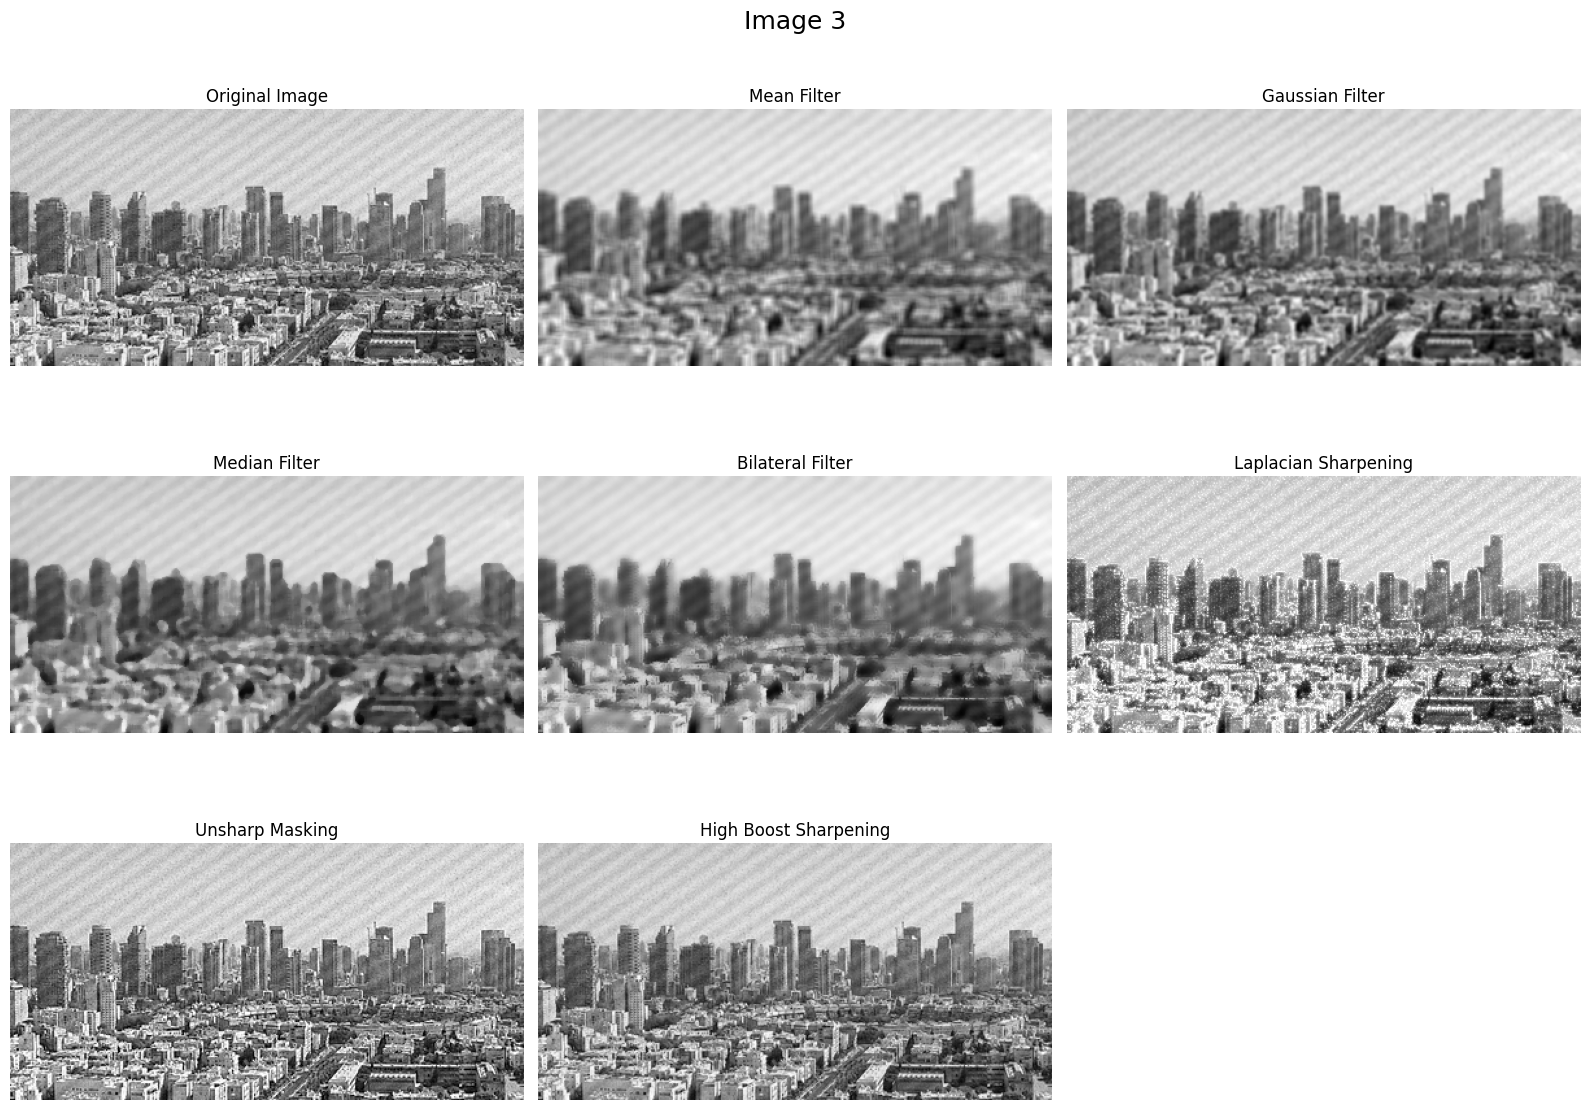

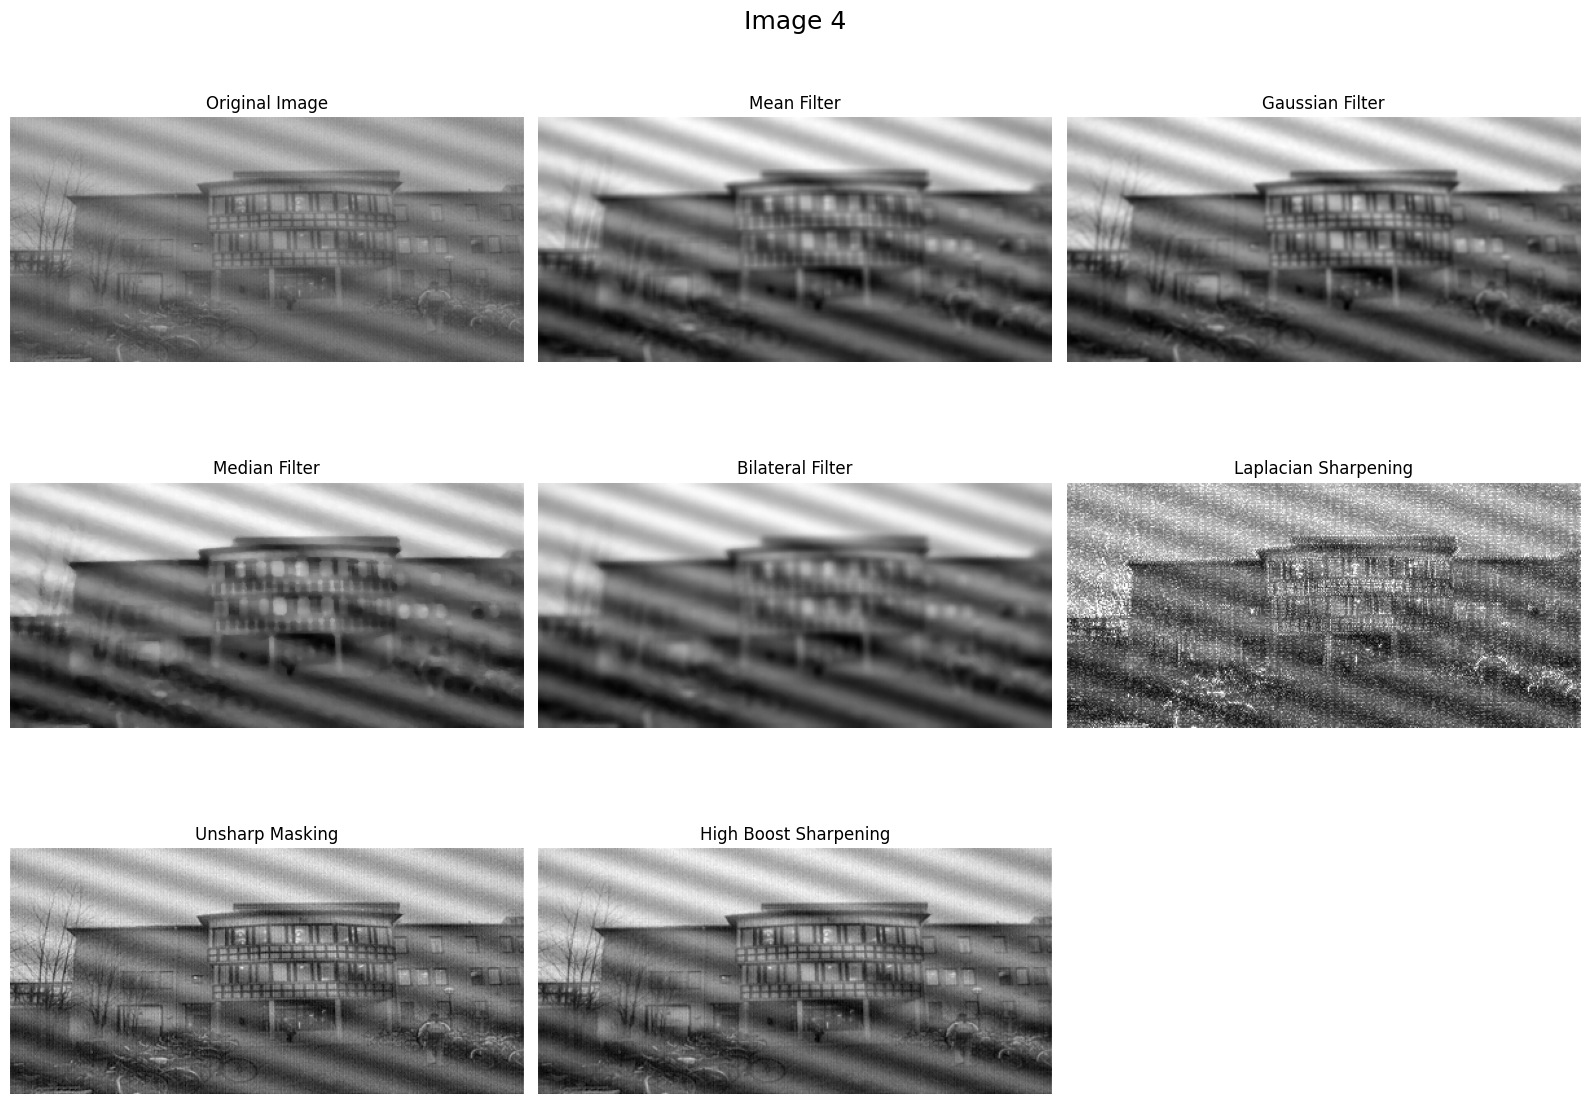

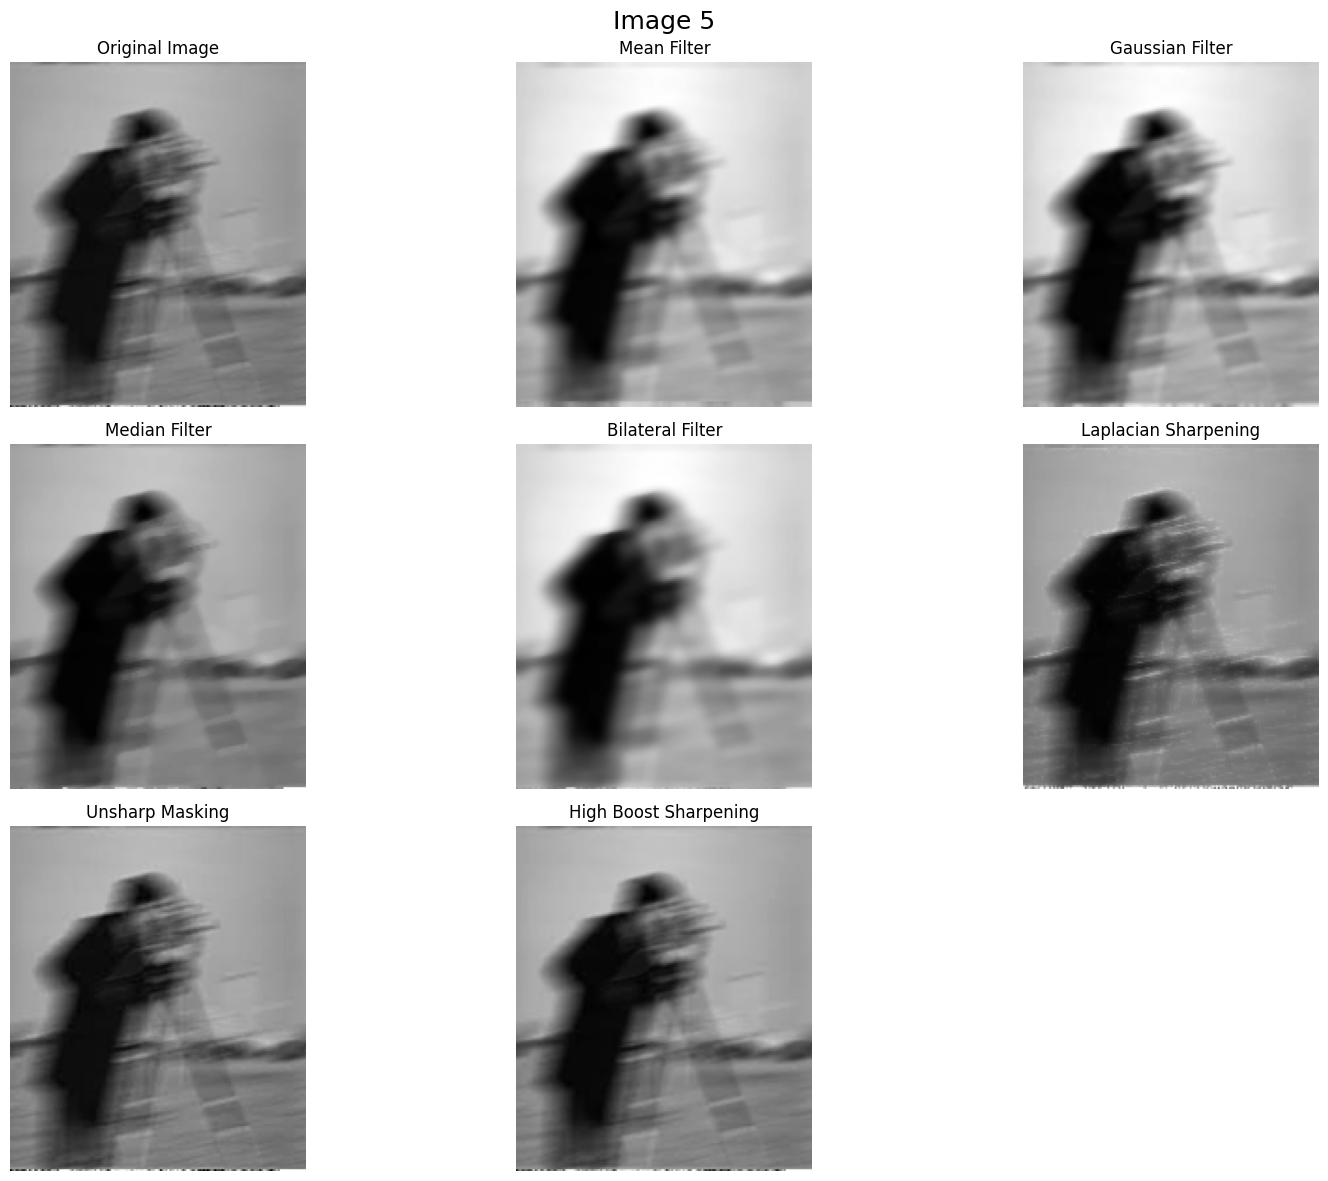

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

image_paths = [
    r"1.png",
    r"2.png",
    r"3.png",
    r"4.png",
    r"5.png"
]

image_names = [
    "Image 1",
    "Image 2",
    "Image 3",
    "Image 4",
    "Image 5"
]

output_folder = r"C:\Users\LADVA\Desktop\SEM 5\DSIP\OPE 9"
os.makedirs(output_folder, exist_ok=True)

for i, image_path in enumerate(image_paths):

    if not os.path.exists(image_path):
        continue

    img = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)

    if img is None:
        continue

    if len(img.shape) == 3 and img.shape[2] == 4:
        b, g, r, alpha = cv2.split(img)

        background = np.ones_like(img[:, :, :3]) * 255
        bgr = cv2.merge([b, g, r])

        alpha_float = alpha.astype(float) / 255.0
        alpha_float = alpha_float[:, :, np.newaxis]

        img = (
            bgr.astype(float) * alpha_float
            + background.astype(float) * (1 - alpha_float)
        ).astype(np.uint8)

    if len(img.shape) == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        original_display = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    else:
        gray = img.copy()
        original_display = img.copy()

    mean_filter = cv2.blur(gray, (5, 5))

    gaussian_filter = cv2.GaussianBlur(gray, (5, 5), 0)

    median_filter = cv2.medianBlur(gray, 5)

    bilateral_filter = cv2.bilateralFilter(
        gray,
        9,
        75,
        75
    )

    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    laplacian = np.absolute(laplacian)

    laplacian = cv2.normalize(
        laplacian,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)

    laplacian_sharp = cv2.addWeighted(
        gray,
        1.0,
        laplacian,
        1.0,
        0
    )

    blur_for_unsharp = cv2.GaussianBlur(gray, (5, 5), 0)

    unsharp = cv2.addWeighted(
        gray,
        1.5,
        blur_for_unsharp,
        -0.5,
        0
    )

    blur_for_highboost = cv2.GaussianBlur(gray, (1, 1), 0)

    high_boost = cv2.addWeighted(
        gray,
        2.0,
        blur_for_highboost,
        -1.0,
        0
    )

    number = i + 1

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_original.png"),
        gray
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_mean.png"),
        mean_filter
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_gaussian.png"),
        gaussian_filter
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_median.png"),
        median_filter
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_bilateral.png"),
        bilateral_filter
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_laplacian.png"),
        laplacian_sharp
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_unsharp.png"),
        unsharp
    )

    cv2.imwrite(
        os.path.join(output_folder, f"image_{number}_highboost.png"),
        high_boost
    )

    plt.figure(figsize=(16, 12))

    plt.subplot(3, 3, 1)
    plt.imshow(original_display, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(3, 3, 2)
    plt.imshow(mean_filter, cmap="gray")
    plt.title("Mean Filter")
    plt.axis("off")

    plt.subplot(3, 3, 3)
    plt.imshow(gaussian_filter, cmap="gray")
    plt.title("Gaussian Filter")
    plt.axis("off")

    plt.subplot(3, 3, 4)
    plt.imshow(median_filter, cmap="gray")
    plt.title("Median Filter")
    plt.axis("off")

    plt.subplot(3, 3, 5)
    plt.imshow(bilateral_filter, cmap="gray")
    plt.title("Bilateral Filter")
    plt.axis("off")

    plt.subplot(3, 3, 6)
    plt.imshow(laplacian_sharp, cmap="gray")
    plt.title("Laplacian Sharpening")
    plt.axis("off")

    plt.subplot(3, 3, 7)
    plt.imshow(unsharp, cmap="gray")
    plt.title("Unsharp Masking")
    plt.axis("off")

    plt.subplot(3, 3, 8)
    plt.imshow(high_boost, cmap="gray")
    plt.title("High Boost Sharpening")
    plt.axis("off")

    plt.suptitle(image_names[i], fontsize=18)
    plt.tight_layout()

    comparison_file = os.path.join(
        output_folder,
        f"image_{number}_comparison.png"
    )

    plt.savefig(
        comparison_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()